## EN3160 Assignment 3

### A.H.T.M. Weerakoon

### 230689A

In [3]:
%pip install --upgrade certifi


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



     ---------------------------------------- 0.0/134.1 kB ? eta -:--:--
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     -------- ---------------------------- 30.7/134.1 kB 640.0 kB/s eta 0:00:01
     ------------------------- ----------- 92.2/134.1 kB 168.9 kB/s eta 0:00:01
     ------------------------- ----------- 92.

### Setup

In [2]:
import ssl, certifi, functools
ssl._create_default_https_context = functools.partial(ssl.create_default_context, cafile=certifi.where())
import os, time, copy, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models
from torchvision.models import ResNet18_Weights
%matplotlib inline

device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available() else 'cpu')
NUM_WORKERS = 0      # 0 is safest in Jupyter (especially on Windows); raise to 2-4 on Linux for speed
torch.manual_seed(0); np.random.seed(0)
print('Device:', device)

Device: cuda


### Question 01

#### Data loading

In [5]:
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

100.0%


#### Network parameters

In [6]:
Din = 3 * 32 * 32      # input size
H = 100                # (a) hidden layer size
K = 10                 # classes

torch.manual_seed(0)
# Xavier-style initialisation: std 1e-5 (as in Listing 1) would make every sigmoid output 0.5
# and the gradient reaching W1 almost zero.
w1 = (torch.randn(Din, H) * np.sqrt(2.0 / (Din + H))).to(device)
b1 = torch.zeros(H, device=device)
w2 = (torch.randn(H, K) * np.sqrt(2.0 / (H + K))).to(device)
b2 = torch.zeros(K, device=device)

# Hyperparameters
epochs = 10            # (c)
lr = 0.05
lr_decay = 0.95
reg = 1e-4

def forward(x):
    h = torch.sigmoid(x.mm(w1) + b1)       # hidden layer
    s = h.mm(w2) + b2                      # class scores (logits)
    return h, s

def accuracy(loader):
    correct = total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1).to(device)
            _, s = forward(x)
            correct += (s.argmax(1).cpu() == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total

#### Training loop

In [7]:
loss_history, epoch_loss, epoch_train_acc, epoch_test_acc = [], [], [], []

for t in range(epochs):
    running_loss, correct, seen = 0.0, 0, 0
    for inputs, labels in trainloader:
        N = inputs.shape[0]
        x = inputs.view(N, -1).to(device)
        labels = labels.to(device)
        y = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, s = forward(x)
        log_p = s - torch.logsumexp(s, dim=1, keepdim=True)        # numerically stable log-softmax
        p = log_p.exp()

        # (b) Cross-entropy loss + L2 regularisation
        loss = -(y * log_p).sum() / N + reg * (torch.sum(w1**2) + torch.sum(w2**2))
        loss_history.append(loss.item())
        running_loss += loss.item()
        correct += (s.argmax(1) == labels).sum().item(); seen += N

        # Backpropagation
        ds = (p - y) / N                        # dL/dS
        dw2 = h.t().mm(ds) + 2 * reg * w2
        db2 = ds.sum(dim=0)
        dh = ds.mm(w2.t())
        dz1 = dh * h * (1 - h)                  # sigmoid derivative
        dw1 = x.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1; b1 -= lr * db1
        w2 -= lr * dw2; b2 -= lr * db2

    epoch_loss.append(running_loss / len(trainloader))
    epoch_train_acc.append(100 * correct / seen)
    epoch_test_acc.append(accuracy(testloader))
    print(f'Epoch {t+1}/{epochs}  loss {epoch_loss[-1]:.4f}  '
          f'train acc {epoch_train_acc[-1]:.2f}%  test acc {epoch_test_acc[-1]:.2f}%')
    lr *= lr_decay

Epoch 1/10  loss 1.8534  train acc 36.08%  test acc 39.62%
Epoch 2/10  loss 1.7314  train acc 40.82%  test acc 41.62%
Epoch 3/10  loss 1.6834  train acc 42.71%  test acc 42.70%
Epoch 4/10  loss 1.6496  train acc 44.00%  test acc 43.24%
Epoch 5/10  loss 1.6220  train acc 45.23%  test acc 44.01%
Epoch 6/10  loss 1.5979  train acc 46.02%  test acc 44.51%
Epoch 7/10  loss 1.5769  train acc 46.81%  test acc 45.38%
Epoch 8/10  loss 1.5574  train acc 47.76%  test acc 45.65%
Epoch 9/10  loss 1.5389  train acc 48.44%  test acc 46.65%
Epoch 10/10  loss 1.5219  train acc 49.05%  test acc 46.29%


#### Plots and final accuracies

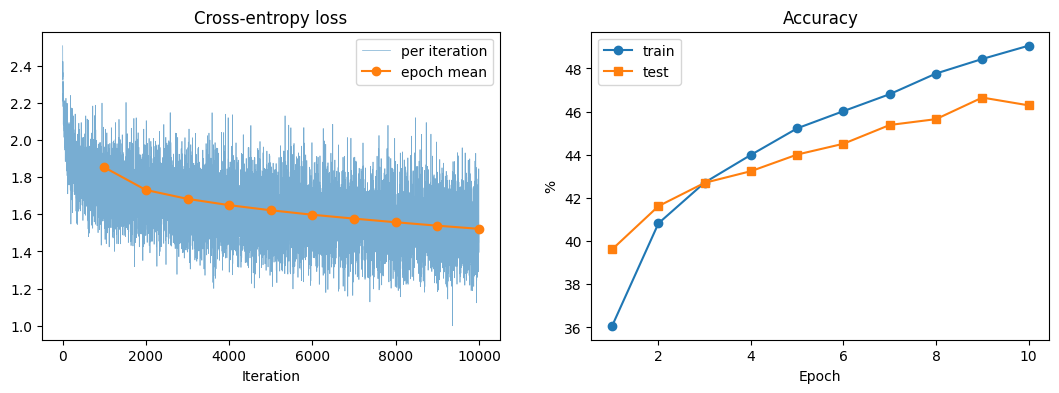

Training accuracy: 50.18%
Test accuracy:     46.29%


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(loss_history, lw=0.5, alpha=0.6, label='per iteration')
ax[0].plot(np.arange(1, epochs + 1) * len(trainloader), epoch_loss, 'o-', label='epoch mean')
ax[0].set_title('Cross-entropy loss'); ax[0].set_xlabel('Iteration'); ax[0].legend()
ax[1].plot(range(1, epochs + 1), epoch_train_acc, 'o-', label='train')
ax[1].plot(range(1, epochs + 1), epoch_test_acc, 's-', label='test')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('%'); ax[1].legend()
plt.show()

train_acc = accuracy(trainloader)
test_acc = accuracy(testloader)
print(f'Training accuracy: {train_acc:.2f}%')
print(f'Test accuracy:     {test_acc:.2f}%')

### Question 02

#### Both models use the same conditions: Adam, learning rate 1e-3, batch size 64, cross-entropy loss, 10 epochs.

#### Data

In [3]:
mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
mnist_train = datasets.MNIST('./data', train=True, download=True, transform=mnist_tf)
mnist_test = datasets.MNIST('./data', train=False, download=True, transform=mnist_tf)
mnist_trainloader = torch.utils.data.DataLoader(mnist_train, batch_size=64, shuffle=True, num_workers=NUM_WORKERS)
mnist_testloader = torch.utils.data.DataLoader(mnist_test, batch_size=1000, shuffle=False, num_workers=NUM_WORKERS)

100.0%
100.0%
100.0%
100.0%


#### (a) LeNet-5 and (b) small CNN

In [4]:
# (a) LeNet-5 (LeCun et al., 1998): 28x28 input padded to 32x32 by padding=2
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Tanh(), nn.AvgPool2d(2),    # 6 x 14 x 14
            nn.Conv2d(6, 16, kernel_size=5), nn.Tanh(), nn.AvgPool2d(2))              # 16 x 5 x 5
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

# (b) Modern small CNN: 3 conv blocks with batch normalisation, ReLU, max pooling, and dropout
def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                         nn.BatchNorm2d(cout), nn.ReLU(inplace=True), nn.MaxPool2d(2))

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 32),      # 32 x 14 x 14
                                      conv_block(32, 64),     # 64 x 7 x 7
                                      conv_block(64, 128))    # 128 x 3 x 3
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.25),
            nn.Linear(128 * 3 * 3, 128), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(128, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

n_params = lambda m: sum(p.numel() for p in m.parameters())
print('LeNet-5 parameters:', n_params(LeNet5()))
print('SmallCNN parameters:', n_params(SmallCNN()))

LeNet-5 parameters: 61706
SmallCNN parameters: 241770


#### Training and evaluation functions

In [5]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, 100 * correct / n

def train_mnist(model, epochs=10, lr=1e-3):
    torch.manual_seed(0)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    t0 = time.time()
    for ep in range(epochs):
        tr_loss, tr_acc = run_epoch(model, mnist_trainloader, criterion, optimizer)
        te_loss, te_acc = run_epoch(model, mnist_testloader, criterion)
        for k, v in zip(hist, (tr_loss, tr_acc, te_loss, te_acc)):
            hist[k].append(v)
        print(f'Epoch {ep+1:2d}/{epochs}  train loss {tr_loss:.4f} acc {tr_acc:.2f}%  |  '
              f'test loss {te_loss:.4f} acc {te_acc:.2f}%')
    hist['time'] = time.time() - t0
    return model, hist

#### Train both models

In [6]:
torch.manual_seed(0)
print('=== LeNet-5 ===')
lenet, hist_lenet = train_mnist(LeNet5())
torch.manual_seed(0)
print('\n=== SmallCNN ===')
cnn, hist_cnn = train_mnist(SmallCNN())

=== LeNet-5 ===
Epoch  1/10  train loss 0.2555 acc 92.62%  |  test loss 0.0877 acc 97.19%
Epoch  2/10  train loss 0.0727 acc 97.81%  |  test loss 0.0666 acc 97.95%
Epoch  3/10  train loss 0.0488 acc 98.53%  |  test loss 0.0655 acc 97.88%
Epoch  4/10  train loss 0.0398 acc 98.77%  |  test loss 0.0438 acc 98.52%
Epoch  5/10  train loss 0.0320 acc 99.03%  |  test loss 0.0517 acc 98.38%
Epoch  6/10  train loss 0.0269 acc 99.14%  |  test loss 0.0442 acc 98.61%
Epoch  7/10  train loss 0.0220 acc 99.27%  |  test loss 0.0415 acc 98.72%
Epoch  8/10  train loss 0.0209 acc 99.33%  |  test loss 0.0513 acc 98.57%
Epoch  9/10  train loss 0.0163 acc 99.47%  |  test loss 0.0421 acc 98.72%
Epoch 10/10  train loss 0.0144 acc 99.52%  |  test loss 0.0520 acc 98.68%

=== SmallCNN ===
Epoch  1/10  train loss 0.1932 acc 94.26%  |  test loss 0.0354 acc 98.87%
Epoch  2/10  train loss 0.0801 acc 97.69%  |  test loss 0.0301 acc 98.95%
Epoch  8/10  train loss 0.0319 acc 99.09%  |  test loss 0.0214 acc 99.32%
Epoc

#### (c) Per-epoch curves and final accuracies

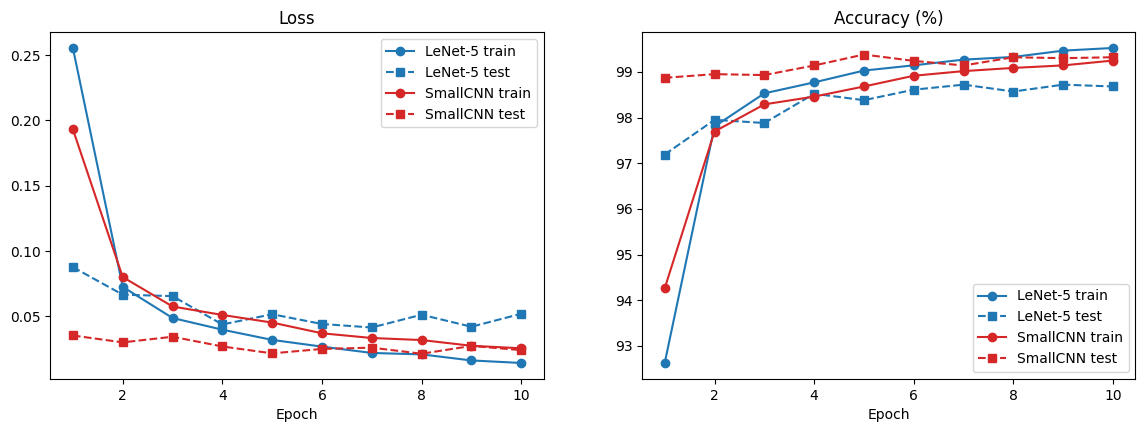

Model        Params  Train acc  Test acc  Time (s)
LeNet-5       61706     99.42%    98.68%     896.4
SmallCNN     241770     99.80%    99.32%    1039.9


In [7]:
ep = range(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, h, c in [('LeNet-5', hist_lenet, 'tab:blue'), ('SmallCNN', hist_cnn, 'tab:red')]:
    ax[0].plot(ep, h['train_loss'], 'o-', color=c, label=f'{name} train')
    ax[0].plot(ep, h['test_loss'], 's--', color=c, label=f'{name} test')
    ax[1].plot(ep, h['train_acc'], 'o-', color=c, label=f'{name} train')
    ax[1].plot(ep, h['test_acc'], 's--', color=c, label=f'{name} test')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].set_title('Accuracy (%)'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.show()

# Final accuracies, train set measured in eval mode (no dropout, BN running stats)
crit = nn.CrossEntropyLoss()
print(f"{'Model':<10} {'Params':>8} {'Train acc':>10} {'Test acc':>9} {'Time (s)':>9}")
for name, m, h in [('LeNet-5', lenet, hist_lenet), ('SmallCNN', cnn, hist_cnn)]:
    _, tr = run_epoch(m, mnist_trainloader, crit)
    _, te = run_epoch(m, mnist_testloader, crit)
    print(f'{name:<10} {n_params(m):>8} {tr:>9.2f}% {te:>8.2f}% {h["time"]:>9.1f}')

#### (c) Confusion matrices

LeNet-5 most frequent confusions (true -> predicted, count): [(7, 9, 15), (0, 6, 7), (7, 2, 7)]
SmallCNN most frequent confusions (true -> predicted, count): [(4, 9, 5), (5, 3, 5), (9, 4, 5)]


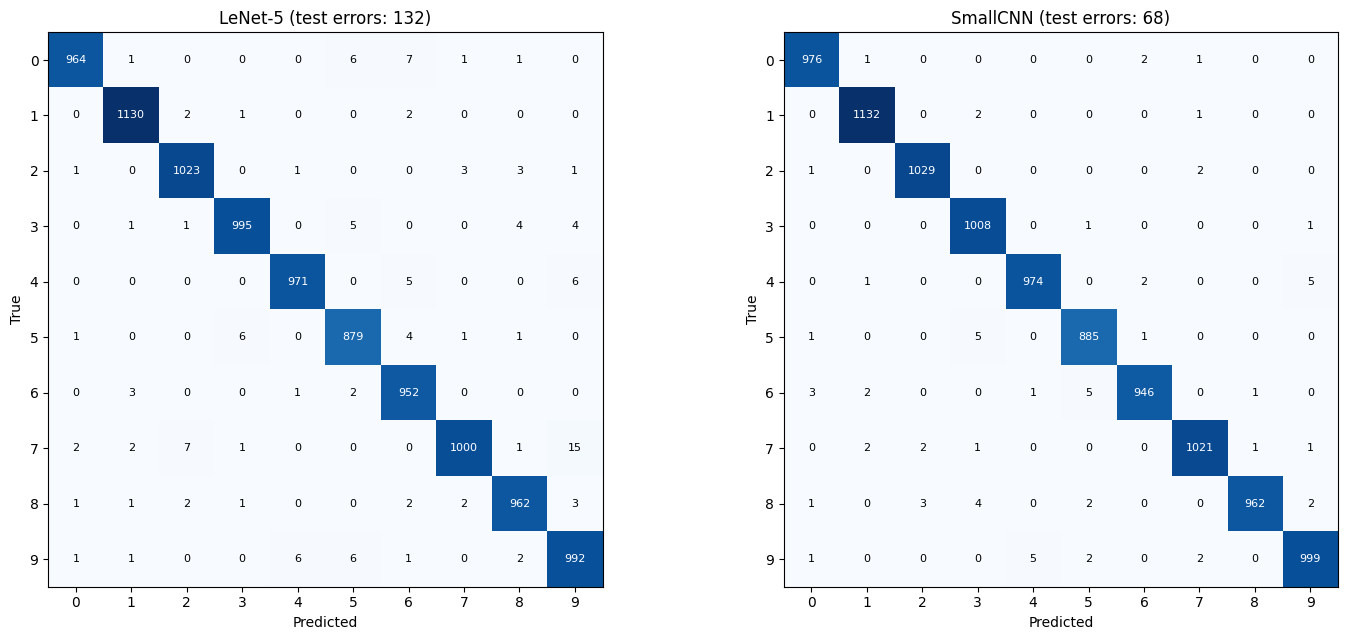

In [8]:
def confusion_matrix(model, loader, K=10):
    cm = torch.zeros(K, K, dtype=torch.long)
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            pred = model(x.to(device)).argmax(1).cpu()
            cm += torch.bincount(y * K + pred, minlength=K * K).view(K, K)
    return cm.numpy()

def plot_cm(cm, title, ax):
    ax.imshow(cm, cmap='Blues')
    ax.set_title(title); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    thr = cm.max() / 2
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                    color='white' if cm[i, j] > thr else 'black')

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
for a, (name, m) in zip(ax, [('LeNet-5', lenet), ('SmallCNN', cnn)]):
    cm = confusion_matrix(m, mnist_testloader)
    plot_cm(cm, f'{name} (test errors: {cm.sum() - np.trace(cm)})', a)
    off = cm.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:3], off.shape))[0]
    print(name, 'most frequent confusions (true -> predicted, count):',
          [(int(i), int(j), int(off[i, j])) for i, j in top])
plt.tight_layout(); plt.show()